# Giai đoạn D – Học máy: chia tập, tiền xử lý, huấn luyện & tinh chỉnh (B9 – B13)
Phương pháp: [`GIAI_DOAN_D_HOC_MAY/`](../QUY_TRINH_DU_AN/GIAI_DOAN_D_HOC_MAY/README.md)

| Bước | Script | Kết quả đọc trong notebook |
|---|---|---|
| B9 Chia tập | `python -m src.ml.split` | `data/splits/split_summary.json` |
| B10 Tiền xử lý | `src/ml/train.py` (`build_pipeline`) | dùng trực tiếp |
| B11 Huấn luyện | `python -m src.ml.experiments` | `reports/model_comparison.csv`, `tuning_*.csv`, `ablation.csv`, `best_model.json`, MLflow `dropout_ews` |
| B12 Đánh giá | `python -m src.ml.evaluate` | `reports/test_metrics.json`, `evaluation_report.md` |
| B13 Giải thích | `python -m src.ml.explain` | `reports/explanation_report.md`, `shap_group_importance.csv`, `shap_*.png` |

Notebook **chỉ đọc kết quả đã lưu**; riêng mục 4 chạy lại CV để phân tích ablation theo cặp fold. Tập **Test chưa được dùng** (để dành cho B12).

In [1]:
import json
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import average_precision_score, precision_recall_curve

from src.ml.experiments import cross_validate, subset_spec
from src.ml.split import load_spec, load_splits

sns.set_theme(style="whitegrid", font_scale=0.95)
FIG_DIR, REP = ROOT / "reports" / "figures", ROOT / "reports"

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / name, dpi=110, bbox_inches="tight")

splits, spec = load_splits(), load_spec()
print(json.dumps(json.loads((ROOT / "data" / "splits" / "split_summary.json").read_text(encoding="utf-8")),
                 ensure_ascii=False, indent=1))

{
 "random_state": 42,
 "rows": {
  "train": 54474,
  "test": 13650,
  "score": 11115
 },
 "students": {
  "train": 14324,
  "test": 3604,
  "score": 11115
 },
 "positives": {
  "train": 5493,
  "test": 1424
 },
 "positive_rate": {
  "train": 0.1008,
  "test": 0.1043
 },
 "n_features": 43,
 "checks_passed": true
}


## 1. B9 – Chia tập
* Chia **theo sinh viên** (`StratifiedGroupKFold`): Train 54.474 dòng / 14.324 SV (10,08% dương), Test 13.650 dòng / 3.604 SV (10,43%); Scoring 11.115 dòng (`Censored = 1`).
* CV 5 fold theo sinh viên trên Train; mọi so sánh và tinh chỉnh dưới đây **chỉ dùng Train**.

## 2. B11 – So sánh mô hình (CV 5 fold, tham số mặc định)

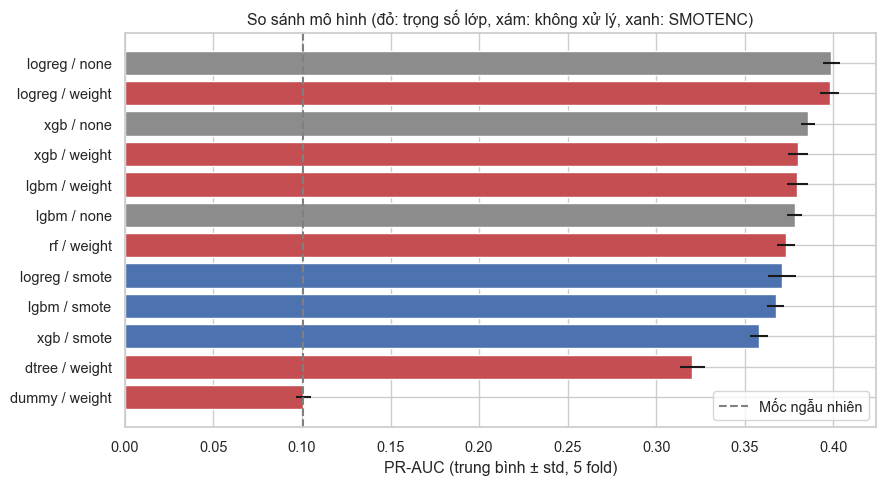

,model,imbalance,pr_auc_mean,pr_auc_std,roc_auc_mean,recall_mean,precision_mean,f1_mean,seconds
6,logreg,none,0.3988,0.0049,0.8008,0.1588,0.6677,0.2565,7.2
1,logreg,weight,0.3980,0.0054,0.8006,0.7023,0.2362,0.3535,7.5
8,xgb,none,0.3857,0.0040,0.7914,0.1746,0.6194,0.2723,16.1
4,xgb,weight,0.3800,0.0054,0.7871,0.6167,0.2627,0.3683,17.3
5,lgbm,weight,0.3797,0.0058,0.7859,0.5939,0.2753,0.3762,14.0
10,lgbm,none,0.3781,0.0044,0.7870,0.1761,0.6047,0.2726,16.2
3,rf,weight,0.3732,0.0053,0.7870,0.5032,0.3254,0.3950,38.1
7,logreg,smote,0.3710,0.0081,0.7803,0.5911,0.2656,0.3665,55.6
11,lgbm,smote,0.3674,0.0047,0.7766,0.2266,0.5301,0.3174,198.5
9,xgb,smote,0.3581,0.0051,0.7717,0.2504,0.4936,0.3322,202.2


In [2]:
cmp_ = pd.read_csv(REP / "model_comparison.csv")
cmp_["cau_hinh"] = cmp_["model"] + " / " + cmp_["imbalance"]
t = cmp_.sort_values("pr_auc_mean")
fig, ax = plt.subplots(figsize=(9, 5))
colors = {"weight": "#C44E52", "none": "#8C8C8C", "smote": "#4C72B0"}
ax.barh(t["cau_hinh"], t["pr_auc_mean"], xerr=t["pr_auc_std"], color=[colors[i] for i in t["imbalance"]])
ax.axvline(t.loc[t["model"] == "dummy", "pr_auc_mean"].iloc[0], color="gray", ls="--", label="Mốc ngẫu nhiên")
ax.set_xlabel("PR-AUC (trung bình ± std, 5 fold)"); ax.legend()
ax.set_title("So sánh mô hình (đỏ: trọng số lớp, xám: không xử lý, xanh: SMOTENC)")
save(fig, "ml_model_comparison.png"); plt.show()
cols = ["model", "imbalance", "pr_auc_mean", "pr_auc_std", "roc_auc_mean", "recall_mean", "precision_mean", "f1_mean", "seconds"]
cmp_[cols].sort_values("pr_auc_mean", ascending=False).round(4)

> **Ghi chú (B13):** mọi con số dưới đây là của lần chạy lại sau khi sửa rò rỉ `Income_Missing` (B4 chỉ ffill; xem mục 8). Lần chạy đầu cao hơn khoảng 0,011 PR-AUC ở mọi mô hình do rò rỉ.

**Nhận xét:**
* Mọi mô hình vượt xa mốc ngẫu nhiên (PR-AUC 0,101). **LogReg dẫn đầu (0,3980 ± 0,0054)**, rồi XGBoost (0,3800) ≈ LightGBM (0,3797) > RF (0,3732) > Decision Tree (0,3204).
* **Trọng số lớp và không xử lý cho cùng PR-AUC** (LogReg 0,3980 so với 0,3988): PR-AUC chỉ phụ thuộc **thứ hạng** xác suất. Trọng số lớp làm xác suất cao lên, nên thay đổi Recall / Precision **tại ngưỡng 0,5** (LogReg: Recall 0,16 → 0,70), không làm mô hình phân biệt tốt hơn. Ngưỡng sẽ được chọn ở B12.
* **SMOTE làm giảm PR-AUC ở cả 3 mô hình** (LogReg 0,398 → 0,371; XGBoost 0,380 → 0,358; LightGBM 0,380 → 0,367) và chậm hơn 7 – 14 lần (xem mục 3).

## 3. Bài học về SMOTE

* **Lần chạy đầu:** SMOTE thường nội suy **mọi** cột, nên sinh ra giá trị không thể có ở cột nhị phân / One-Hot / cột đếm (`Scholarship = 0,43`, `Semester = 2,37`). Mô hình cây tách được dòng tổng hợp chỉ bằng một ngưỡng: XGBoost học trên dữ liệu "50% dương" nhưng dự đoán trung bình chỉ **0,105**, kể cả trên chính tập huấn luyện. SMOTE mất tác dụng mà không báo lỗi.
* **Sửa:** `DiscreteAwareSMOTE` (trong `src/ml/train.py`) tự phát hiện cột rời rạc và dùng **SMOTENC** (lấy giá trị phổ biến của láng giềng thay vì nội suy). Có unit test kiểm tra mẫu tổng hợp giữ số nguyên ở cột rời rạc.
* **Sau khi sửa, SMOTE vẫn kém hơn trọng số lớp**, vì nhiều đặc trưng có **ràng buộc logic** (`Delta_GPA = Sem_GPA − GPA_prev`, kỳ 1 thì không có `GPA_prev`…). Nội suy phá vỡ các ràng buộc này, tạo ra tổ hợp "không thể tồn tại".
* ⇒ **Chọn trọng số lớp** cho mô hình cuối. Bài học: kỹ thuật cân bằng phải phù hợp với **cấu trúc đặc trưng**, không chỉ với tỷ lệ lớp.

## 4. B11 – Tinh chỉnh bằng Optuna

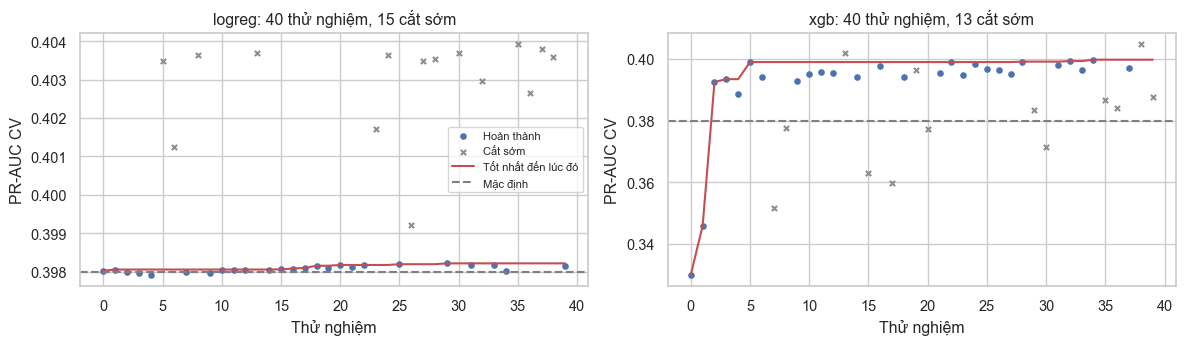

,pr_auc_mean,pr_auc_std,C,n_estimators,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree,reg_lambda
logreg,0.398214,0.005377,0.010768,NaN,NaN,NaN,NaN,NaN,NaN,NaN
xgb,0.399761,0.006681,NaN,850.0,0.018628,2.0,22.151225,0.778103,0.937104,0.099899


In [3]:
tuned = json.loads((REP / "tuned_models.json").read_text(encoding="utf-8"))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, name in zip(axes, tuned):
    tr = pd.read_csv(REP / f"tuning_{name}.csv")
    done = tr[tr["state"] == "COMPLETE"]
    ax.scatter(tr.index, tr["value"].where(tr["state"] == "COMPLETE"), s=14, label="Hoàn thành", color="#4C72B0")
    ax.scatter(tr.index, tr["value"].where(tr["state"] == "PRUNED"), s=14, marker="x", label="Cắt sớm", color="#8C8C8C")
    ax.plot(tr.index, tr["value"].where(tr["state"] == "COMPLETE").cummax().ffill(), color="#C44E52", label="Tốt nhất đến lúc đó")
    base = cmp_[(cmp_["model"] == name) & (cmp_["imbalance"] == "weight")]["pr_auc_mean"].iloc[0]
    ax.axhline(base, color="gray", ls="--", label="Mặc định")
    ax.set_title(f"{name}: {len(tr)} thử nghiệm, {int((tr['state'] == 'PRUNED').sum())} cắt sớm")
    ax.set_xlabel("Thử nghiệm"); ax.set_ylabel("PR-AUC CV")
axes[0].legend(fontsize=8)
save(fig, "ml_tuning_history.png"); plt.show()
pd.DataFrame({k: {"pr_auc_mean": v["pr_auc_mean"], "pr_auc_std": v["pr_auc_std"], **v["params"]} for k, v in tuned.items()}).T

**Nhận xét:**
* Optuna (TPE + MedianPruner, 40 thử nghiệm mỗi mô hình): XGBoost tăng từ **0,3800 lên 0,3998**; LogReg gần như không đổi (0,3980 → 0,3982) dù `C` chọn được là **0,011** (chính quy hóa mạnh): mặt PR-AUC theo `C` rất phẳng.
* Tham số tốt nhất của XGBoost là **`max_depth = 2`** (cây rất nông, nhiều cây, `learning_rate` nhỏ). Cây sâu mặc định (`max_depth = 5`) học quá kỹ. Cây nông nghĩa là mô hình chủ yếu cộng dồn tác động của từng đặc trưng, gần với mô hình tuyến tính.
* Sau tinh chỉnh, **XGBoost nhỉnh hơn LogReg 0,0016** (một seed), nhỏ hơn độ lệch chuẩn giữa các fold (~0,005 – 0,007). So sánh kỹ hơn ở mục 6.

## 5. B11 – Ablation: đặc trưng chiều dọc có giúp không?

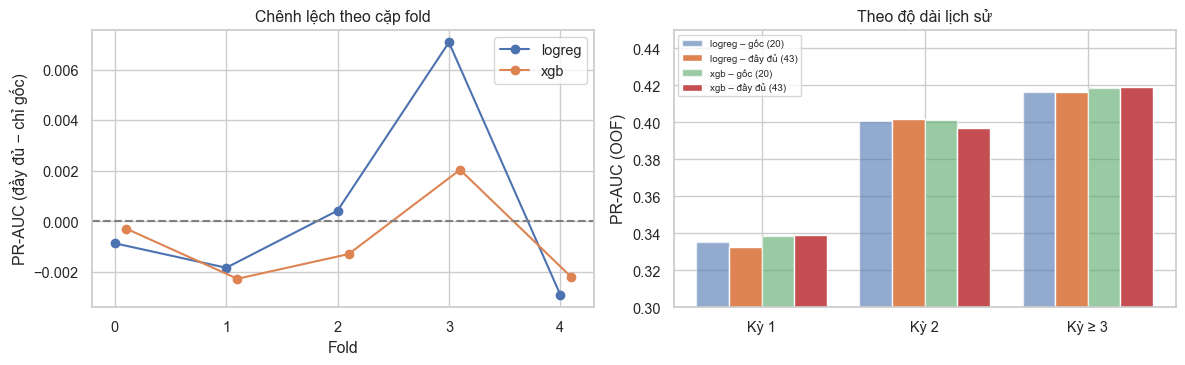

,model,feature_set,n_features,pr_auc_mean,pr_auc_std,roc_auc_mean
0,logreg,baseline,20,0.3978,0.0051,0.8007
1,logreg,full,43,0.3982,0.0054,0.8008
2,xgb,baseline,20,0.4006,0.0053,0.8014
3,xgb,full,43,0.3998,0.0067,0.8003


,mean,std,so_fold_tot_hon
model,,,
logreg,0.0004,0.0039,2
xgb,-0.0008,0.0018,1


,model,nhom,so_dong,goc,day_du
0,logreg,kỳ 1,14324,0.3351,0.3326
1,logreg,kỳ 2,11730,0.4005,0.4015
2,logreg,kỳ ≥ 3,28420,0.4161,0.4163
3,xgb,kỳ 1,14324,0.3387,0.3388
4,xgb,kỳ 2,11730,0.4011,0.3970
5,xgb,kỳ ≥ 3,28420,0.4184,0.4188


In [4]:
abl = pd.read_csv(REP / "ablation.csv")
base_spec = subset_spec(spec, spec["baseline_features"])
sem = splits.X_train["Semester"].values
paired, by_sem = [], []
for name in tuned:
    rb = cross_validate(name, splits.X_train[base_spec["features"]], splits.y_train, splits.groups_train,
                        base_spec, "weight", tuned[name]["params"], feature_set="baseline")
    rf = cross_validate(name, splits.X_train, splits.y_train, splits.groups_train, spec, "weight",
                        tuned[name]["params"], feature_set="full")
    for k, (fb, ff) in enumerate(zip(rb.folds, rf.folds)):
        paired.append({"model": name, "fold": k, "goc": fb["pr_auc"], "day_du": ff["pr_auc"],
                       "chenh_lech": ff["pr_auc"] - fb["pr_auc"]})
    for label, mask in (("kỳ 1", sem == 1), ("kỳ 2", sem == 2), ("kỳ ≥ 3", sem >= 3)):
        y = splits.y_train.values[mask]
        by_sem.append({"model": name, "nhom": label, "so_dong": int(mask.sum()),
                       "goc": average_precision_score(y, rb.oof[mask]),
                       "day_du": average_precision_score(y, rf.oof[mask])})
paired, by_sem = pd.DataFrame(paired), pd.DataFrame(by_sem)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for i, name in enumerate(tuned):
    p = paired[paired["model"] == name]
    axes[0].plot(p["fold"] + i * 0.1, p["chenh_lech"], "o-", label=name)
axes[0].axhline(0, color="gray", ls="--"); axes[0].set_xlabel("Fold")
axes[0].set_ylabel("PR-AUC (đầy đủ − chỉ gốc)"); axes[0].set_title("Chênh lệch theo cặp fold"); axes[0].legend()
x = np.arange(3); w = 0.2
for i, name in enumerate(tuned):
    b = by_sem[by_sem["model"] == name]
    axes[1].bar(x + (2 * i - 1.5) * w, b["goc"], w, label=f"{name} – gốc (20)", alpha=0.6)
    axes[1].bar(x + (2 * i - 0.5) * w, b["day_du"], w, label=f"{name} – đầy đủ (43)")
axes[1].set_xticks(x, ["Kỳ 1", "Kỳ 2", "Kỳ ≥ 3"]); axes[1].set_ylim(0.3, 0.45)
axes[1].set_ylabel("PR-AUC (OOF)"); axes[1].set_title("Theo độ dài lịch sử"); axes[1].legend(fontsize=7)
save(fig, "ml_ablation.png"); plt.show()
display(abl[["model", "feature_set", "n_features", "pr_auc_mean", "pr_auc_std", "roc_auc_mean"]].round(4))
display(paired.groupby("model")["chenh_lech"].agg(["mean", "std", lambda s: int((s > 0).sum())]).rename(columns={"<lambda_0>": "so_fold_tot_hon"}).round(4))
by_sem.round(4)

**Kết quả (trái với giả thuyết ban đầu của đề tài):**
* **Đặc trưng chiều dọc không cải thiện khả năng dự báo.**
  * LogReg: 0,3978 (20 đặc trưng gốc) → 0,3982 (43 đặc trưng), chỉ tốt hơn ở **2/5** fold.
  * XGBoost: 0,4006 → 0,3998, chỉ tốt hơn ở **1/5** fold.
  * Mọi chênh lệch đều nằm trong mức dao động ngẫu nhiên giữa các fold.
* Kể cả với sinh viên có **lịch sử dài** (kỳ ≥ 3, 28.420 dòng), nơi đặc trưng chiều dọc có nhiều thông tin nhất: 0,4161 so với 0,4163 (LogReg).
* **Cách hiểu:** EDA (B6) cho thấy nhóm sắp bỏ học **sa sút dần** qua các kỳ. Nhưng sự sa sút đó **đã thể hiện sẵn trong giá trị hiện tại** (GPA thấp, nợ môn, áp lực tài chính cao). Biết trạng thái hiện tại thì quỹ đạo không thêm thông tin, tức là trong bộ dữ liệu này, rủi ro bỏ học kỳ sau phụ thuộc chủ yếu vào **trạng thái hiện tại**.
* **Kiểm chứng thêm** (3 seed × 5 fold = 15 cặp fold):
  * LogReg: chênh lệch +0,0003, khoảng tin cậy ~95% [−0,0018; +0,0023], chứa 0 (tốt hơn 8/15 fold).
  * XGBoost: −0,0014 [−0,0024; −0,0004].
  * Pipeline có đủ 47 cột (so với 24), nên không có lỗi làm rơi đặc trưng.
  * Chỉ dùng 23 đặc trưng chiều dọc vẫn đạt PR-AUC 0,352, tức là chúng **có thông tin nhưng trùng** với trạng thái hiện tại.
* **Ý nghĩa cho đề tài:**
  * Đây là một **kết quả âm có giá trị**, kiểm chứng bằng thí nghiệm có đối chứng, thay vì mặc định "thêm đặc trưng thì tốt hơn".
  * Đặc trưng chiều dọc vẫn hữu ích cho **mô tả và diễn giải** (EDA, luật kết hợp `GPA_Low + GPA_Drop` ở B8, lý do cảnh báo dễ hiểu cho cố vấn), dù không tăng độ chính xác.

## 6. Mô hình được chọn & dự đoán out-of-fold

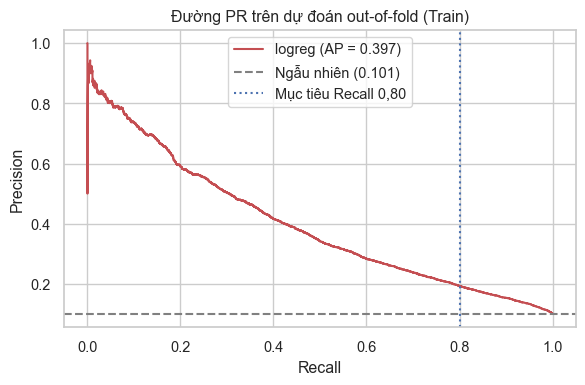

{"model": "logreg", "imbalance": "weight", "feature_set": "full", "params": {"C": 0.010768179105208237}, "best_by_cv": "xgb", "cv_by_model": {"xgb": 0.39976077178711183, "logreg": 0.39821405525080383}}
Precision tại Recall ≈ 0,80: 0.193


In [5]:
best = json.loads((REP / "best_model.json").read_text(encoding="utf-8"))
oof = pd.read_parquet(ROOT / best["oof_path"])
prec, rec, _ = precision_recall_curve(oof["y"], oof["oof_proba"])
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(rec, prec, color="#C44E52", label=f"{best['model']} (AP = {average_precision_score(oof['y'], oof['oof_proba']):.3f})")
ax.axhline(oof["y"].mean(), color="gray", ls="--", label=f"Ngẫu nhiên ({oof['y'].mean():.3f})")
ax.axvline(0.8, color="#4C72B0", ls=":", label="Mục tiêu Recall 0,80")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_title("Đường PR trên dự đoán out-of-fold (Train)"); ax.legend()
save(fig, "ml_oof_pr_curve.png"); plt.show()
print(json.dumps({k: best[k] for k in ("model", "imbalance", "feature_set", "params", "best_by_cv", "cv_by_model")}, ensure_ascii=False))
print(f"Precision tại Recall ≈ 0,80: {prec[np.argmin(np.abs(rec - 0.8))]:.3f}")

**Lựa chọn:** **Logistic Regression** (`C = 0,011`, 43 đặc trưng), PR-AUC CV **0,3982 ± 0,0054**, ROC-AUC 0,801. Lựa chọn được ghi trong `config/settings.yaml` (`model.final`); `best_model.json` ghi cả mô hình có CV cao nhất (`best_by_cv`) để minh bạch.
* **So sánh theo cặp** (3 seed × 5 fold, cùng cách chia): XGBoost tinh chỉnh (không trọng số lớp) hơn LogReg **+0,0028** PR-AUC, khoảng tin cậy 95% [+0,0011; +0,0046], thắng 13/15 fold. Chênh lệch **có ý nghĩa thống kê nhưng rất nhỏ** (~0,7%), nhỏ hơn nhiều dao động giữa các fold (~0,015).
* Nhóm **giữ LogReg** vì **đơn giản, nhanh, ổn định** và **giải thích chính xác** (hệ số / LinearSHAP, mục 8). XGBoost là phương án dự phòng.
* *Ghi chú:* trước khi sửa rò rỉ `Income_Missing`, LogReg nhỉnh hơn (0,4097 so với 0,4090). Rò rỉ là một cờ nhị phân có hệ số lớn, loại tín hiệu mô hình tuyến tính khai thác rất dễ, nên nó giúp LogReg nhiều hơn một chút.
* Dự đoán out-of-fold (`data/models/oof_best.parquet`) dùng để **chọn ngưỡng ở B12** mà không chạm vào Test. Tại Recall 0,80, Precision chỉ khoảng 0,19, tức khoảng 5 cảnh báo thì 1 đúng. Đây là đánh đổi cần cân nhắc khi chọn ngưỡng.

## 7. B12 – Hiệu chỉnh, chọn ngưỡng & đánh giá trên Test
Chạy bằng `python -m src.ml.evaluate`. Phần này **chỉ đọc kết quả đã lưu** (`reports/test_metrics.json`, `config/risk_thresholds.json`, biểu đồ `eval_*.png`), **không dự đoán lại trên Test**.

> Tập Test đã được đánh giá **2 lần**: lần 1 (PR-AUC 0,4002) bị thay thế sau khi B13 phát hiện rò rỉ `Income_Missing`. Cấu hình (LogReg, chính sách ngưỡng) chốt trên Train trước cả hai lần; lý do ghi trong `evaluation_report.md` và tag MLflow.

**Hiệu chỉnh xác suất** (so sánh trên OOF của Train, CV lồng nhau):

| Phương án | PR-AUC | Brier | Xác suất TB (thật 0,1008) |
|---|---:|---:|---:|
| Trọng số lớp, không hiệu chỉnh | 0,3969 | 0,1773 | 0,391 |
| Trọng số lớp + isotonic | 0,3940 | 0,0750 | 0,101 |
| Trọng số lớp + sigmoid | 0,3967 | 0,0749 | 0,101 |
| **Không trọng số, không hiệu chỉnh** | **0,3973** | **0,0749** | **0,101** |
| Không trọng số + isotonic | 0,3938 | 0,0750 | 0,101 |

⇒ Dùng **LogReg không trọng số lớp**: LogReg học bằng log-loss nên xác suất vốn đã hiệu chỉnh tốt. Trọng số lớp chỉ đẩy xác suất lên rồi lại phải kéo về. Mất cân bằng lớp được xử lý bằng **ngưỡng**.

Mốc rủi ro (chọn trên OOF Train): {'medium': 0.0717, 'high': 0.3175} | số lần đánh giá Test: 2


,OOF Train,Test
PR-AUC,0.3973,0.3914
ROC-AUC,0.8004,0.8079
Brier,0.0749,0.0777
Recall@TB,0.8001,0.8195
Precision@TB,0.1933,0.2049
%≥TB,0.4174,0.4172
Recall@Cao,0.3088,0.2732
Precision@Cao,0.5000,0.4974
%Cao,0.0623,0.0573


,so_dong,so_bo_hoc,ty_le_bo_hoc_thuc,ty_le_dong,ty_le_ca_bo_hoc_bat_duoc
muc,,,,,
Thấp,7955,257,0.032,0.583,0.180
Trung bình,4913,778,0.158,0.360,0.546
Cao,782,389,0.497,0.057,0.273


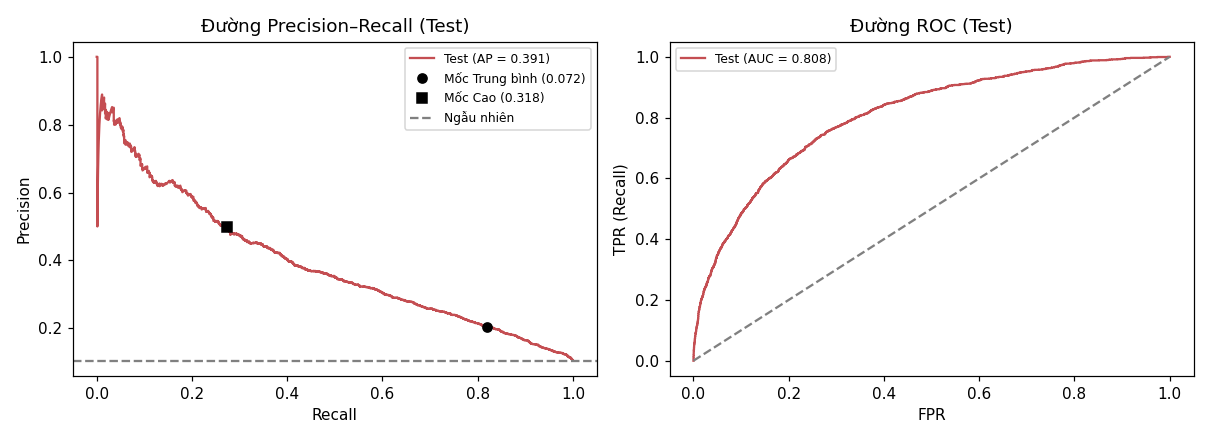

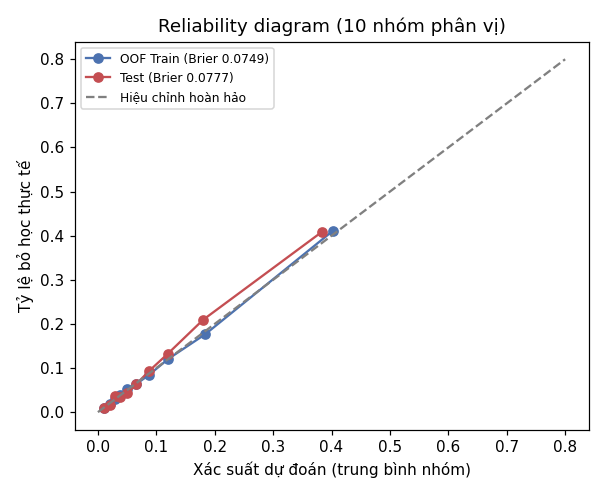

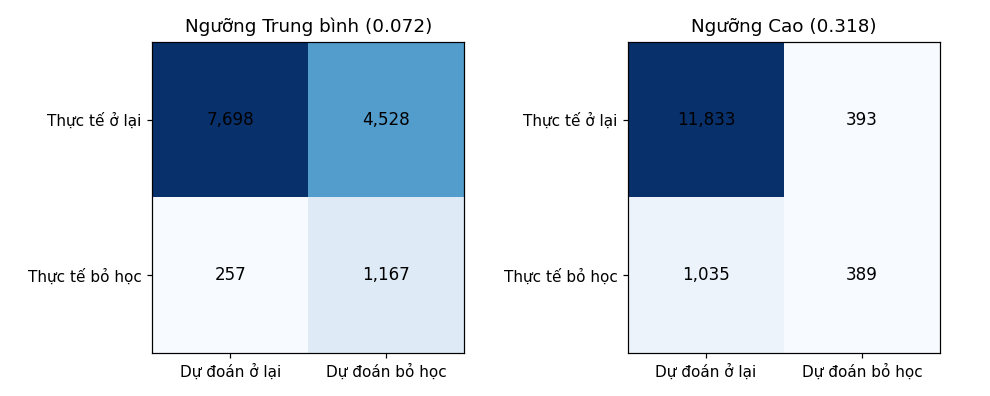

In [6]:
from IPython.display import Image, display
res = json.loads((REP / "test_metrics.json").read_text(encoding="utf-8"))
thr = json.loads((ROOT / "config" / "risk_thresholds.json").read_text(encoding="utf-8"))
print("Mốc rủi ro (chọn trên OOF Train):", {k: round(thr[k], 4) for k in ("medium", "high")}, "| số lần đánh giá Test:", res["test_runs"])
rows = {}
for name, key in (("OOF Train", "oof"), ("Test", "test")):
    m = res[key]
    rows[name] = {"PR-AUC": m["pr_auc"], "ROC-AUC": m["roc_auc"], "Brier": m["brier"],
                  "Recall@TB": m["at_medium"]["recall"], "Precision@TB": m["at_medium"]["precision"], "%≥TB": m["at_medium"]["alert_rate"],
                  "Recall@Cao": m["at_high"]["recall"], "Precision@Cao": m["at_high"]["precision"], "%Cao": m["at_high"]["alert_rate"]}
display(pd.DataFrame(rows).round(4))
display(pd.DataFrame(res["levels"]).set_index("muc").round(3))
for f in ("eval_pr_roc.png", "eval_calibration.png", "eval_confusion.png"):
    display(Image(filename=str(FIG_DIR / f)))

**Kết quả trên Test** (3.604 sinh viên không dùng khi huấn luyện):
* **PR-AUC 0,391**, ROC-AUC 0,808, Brier 0,078, sát với OOF (0,397 / 0,800 / 0,075) nên **không có dấu hiệu overfit**. Xác suất được hiệu chỉnh tốt trên cả Test (reliability diagram sát đường chéo).
* **Ba mức rủi ro:**
  * **Cao** (≥ 0,318): 5,7% sinh viên, **49,7%** trong số đó thật sự bỏ học (gấp ~4,8 lần mức nền), chiếm 27,3% tổng số ca bỏ học.
  * **Trung bình** (0,072 – 0,318): 36,0% sinh viên, 15,8% bỏ học, chiếm 54,6% số ca.
  * **Thấp**: 58,3% sinh viên, chỉ 3,2% bỏ học.
* **Recall tại mốc Trung bình = 0,820** (đạt mục tiêu 0,80 của B0), đổi lại phải theo dõi 41,7% sinh viên. Phân tầng Cao / Trung bình giúp dồn nguồn lực cố vấn vào ~6% sinh viên rủi ro nhất.

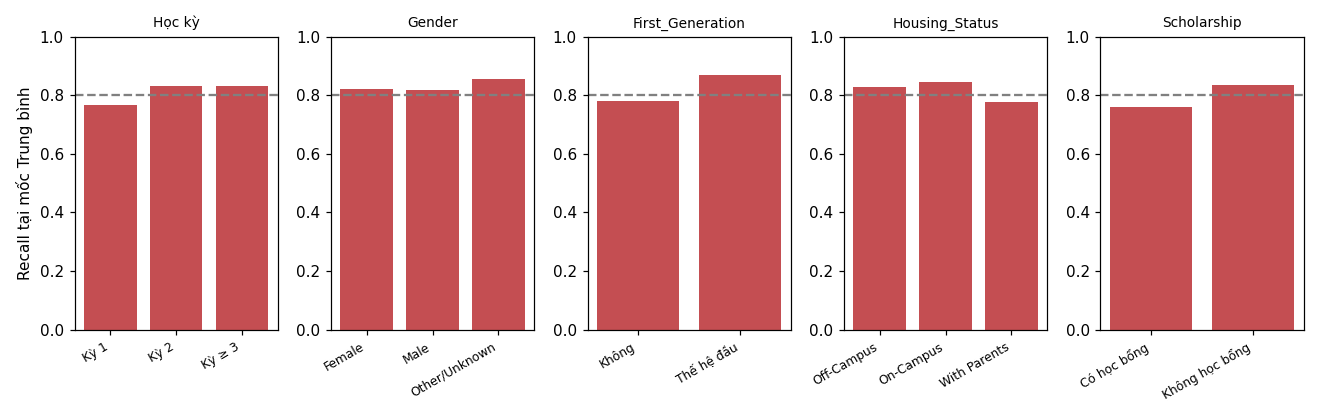

,chieu,nhom,so_dong,ty_le_bo_hoc,recall,precision,pr_auc
0,Học kỳ,Kỳ 1,3604,0.071,0.766,0.179,0.346
1,Học kỳ,Kỳ 2,2974,0.116,0.831,0.241,0.430
2,Học kỳ,Kỳ ≥ 3,7072,0.117,0.831,0.201,0.392
3,Gender,Female,6819,0.106,0.820,0.205,0.393
4,Gender,Male,6574,0.101,0.817,0.203,0.387
5,Gender,Other/Unknown,257,0.136,0.857,0.238,0.474
6,First_Generation,Không,9020,0.088,0.780,0.198,0.373
7,First_Generation,Thế hệ đầu,4630,0.136,0.870,0.214,0.415
8,Housing_Status,Off-Campus,4010,0.107,0.829,0.205,0.381
9,Housing_Status,On-Campus,5283,0.108,0.844,0.207,0.407


,bo_sot_FN,bat_duoc_TP,o_lai
Sem_GPA,2.80,2.27,2.74
Failed_Courses,0.39,1.36,0.60
Financial_Stress,2.09,4.20,2.44
Work_Hours,15.37,22.98,16.46
Attendance,85.52,82.68,85.51
Semester,3.02,3.37,3.03
Family_Income,69192.16,44582.47,63117.50


In [7]:
fair = pd.DataFrame(res["fairness"])
display(Image(filename=str(FIG_DIR / "eval_fairness.png")))
display(fair.round(3))
pd.DataFrame(res["missed"])

**Công bằng & lỗi:**
* **Giới tính:** Recall gần như bằng nhau (Nữ 0,820, Nam 0,817), nên không có thiên lệch theo giới.
* **Nhóm có Recall thấp hơn mục tiêu:** sinh viên **có học bổng** (0,759), **kỳ 1** (0,766), **sống cùng bố mẹ** (0,776), **không phải thế hệ đầu** (0,780). Đây đều là nhóm rủi ro nền thấp, nên mô hình ít cảnh báo hơn. Nếu nhà trường muốn Recall đồng đều, có thể đặt ngưỡng riêng cho từng nhóm, đổi lại báo động giả tăng.
* **Ca bỏ sót trông giống sinh viên bình thường:** GPA 2,80 (cao hơn cả nhóm ở lại, 2,74), ít trượt môn (0,39), áp lực tài chính thấp (2,09), thu nhập cao (~69.200). Nguyên nhân bỏ học của họ **không thể hiện trong dữ liệu** (lý do cá nhân, sức khỏe…). Đây là giới hạn của dữ liệu, không phải của mô hình.
* **Đối chứng phụ** (không dùng để chọn): trên Test, LogReg 43 đặc trưng 0,3914 so với chỉ đặc trưng gốc 0,3874 (+0,004, vẫn nhỏ) và XGBoost 0,3950. Kết luận của B11 giữ nguyên.
* **Mô hình đã đăng ký:** MLflow Model Registry `dropout_model` **v2**, alias **`production`** (v1 là bản có rò rỉ); tải lại bằng `models:/dropout_model@production` cho kết quả khớp.

## 8. B13 – Giải thích mô hình bằng SHAP
Chạy bằng `python -m src.ml.explain`. LogReg → `shap.LinearExplainer` (chính xác: φ_j = β_j (x_j − E[x_j]) trên log-odds, nền = Train). SHAP được **gom theo 13 nhóm khái niệm** vì các biến cùng nhóm tương quan rất mạnh và LogReg chia hệ số giữa chúng (có biến ngược dấu); các cột One-Hot được cộng về biến gốc. Phần này đọc kết quả đã lưu.

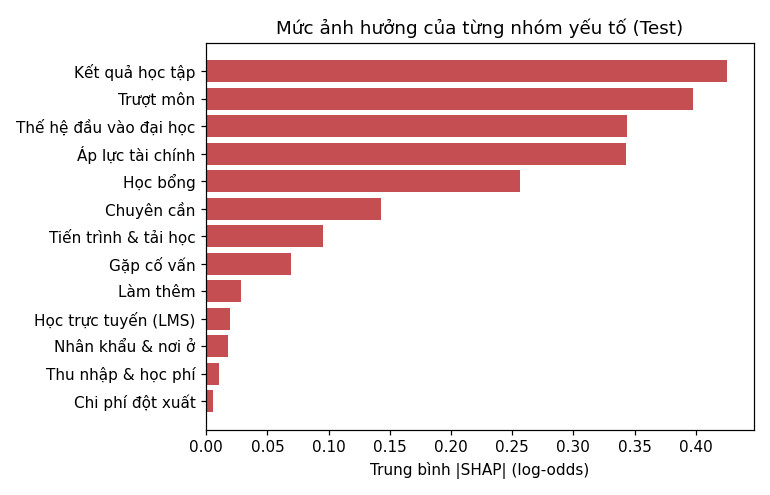

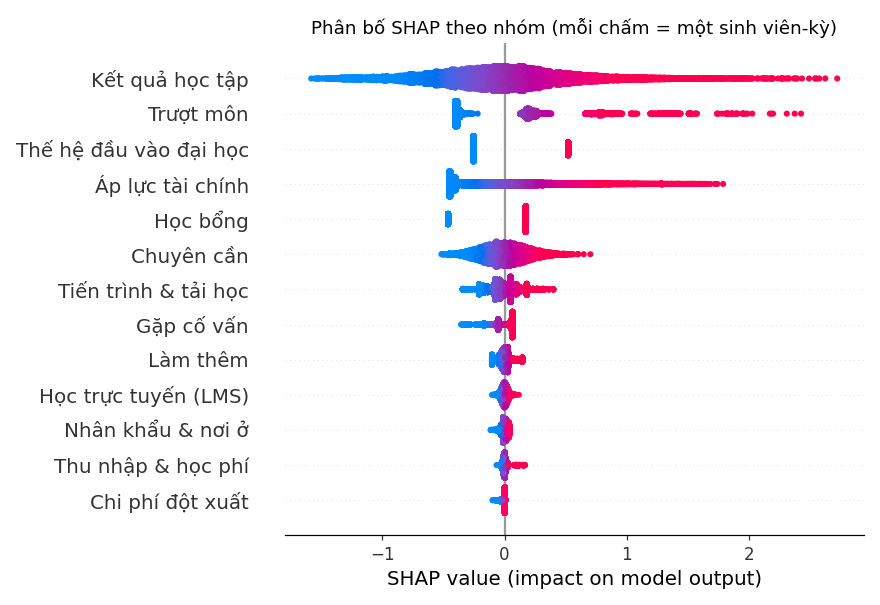

,nhom,ten,mean_abs_shap,ty_le,top1_muc_cao
0,hoc_tap,Kết quả học tập,0.426,0.198,0.471
1,truot_mon,Trượt môn,0.397,0.184,0.315
2,the_he_dau,Thế hệ đầu vào đại học,0.344,0.160,0.005
3,ap_luc_tai_chinh,Áp lực tài chính,0.343,0.159,0.208
4,hoc_bong,Học bổng,0.256,0.119,0.000
5,chuyen_can,Chuyên cần,0.143,0.066,0.001
6,tien_trinh,Tiến trình & tải học,0.096,0.044,0.000
7,co_van,Gặp cố vấn,0.070,0.032,0.000
8,lam_them,Làm thêm,0.028,0.013,0.000
9,lms,Học trực tuyến (LMS),0.019,0.009,0.000


In [8]:
from IPython.display import Image, display
grp = pd.read_csv(REP / "shap_group_importance.csv")
display(Image(filename=str(FIG_DIR / "shap_groups_bar.png")))
display(Image(filename=str(FIG_DIR / "shap_groups_beeswarm.png")))
grp.round(3)

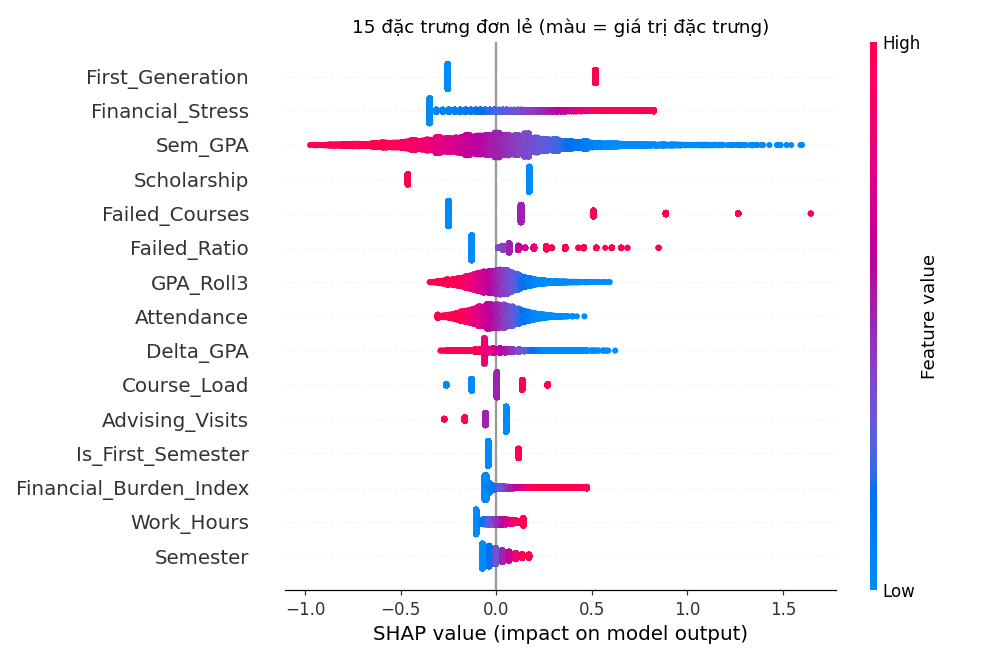

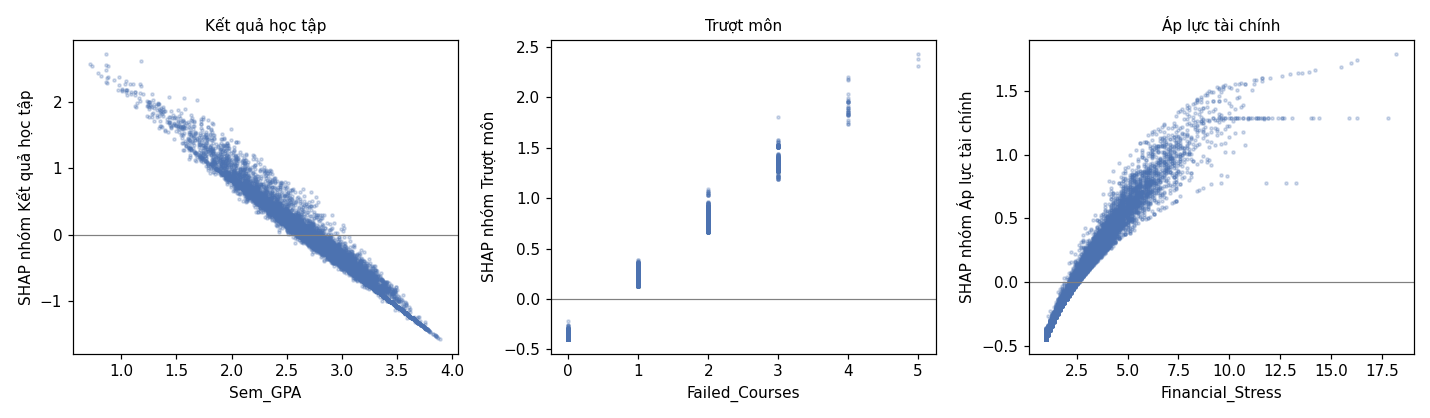

In [9]:
display(Image(filename=str(FIG_DIR / "shap_features_beeswarm.png")))
display(Image(filename=str(FIG_DIR / "shap_dependence.png")))

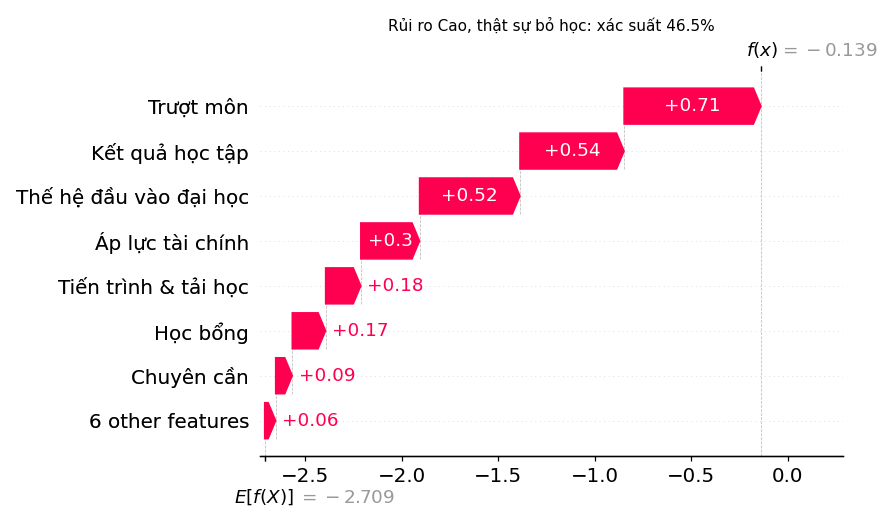

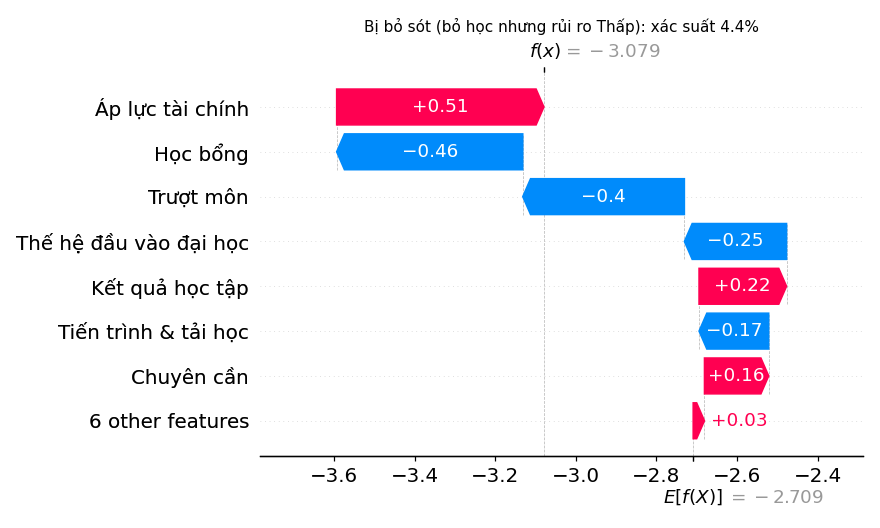

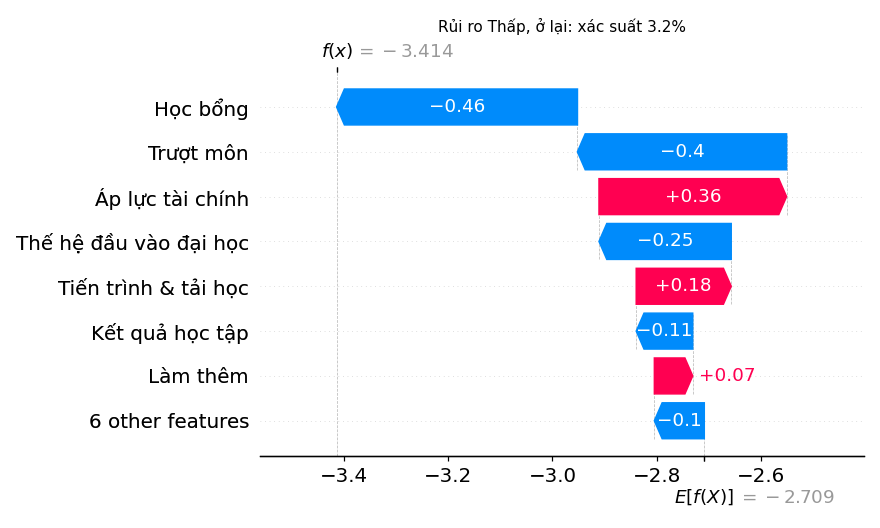

## 3. Kiểm tra rò rỉ

| Kiểm tra | Kết quả | Chi tiết |
|---|:---:|---|
| Không biến nào chiếm > 30% tổng |SHAP| | ✅ | lớn nhất: First_Generation 13.0% |
| Income_Missing (hiếm, 1.47% dòng) không đẩy log-odds > 2 | ✅ | SHAP trung bình khi = 1: +0.11 |
| LMS_Missing (hiếm, 1.06% dòng) không đẩy log-odds > 2 | ✅ | SHAP trung bình khi = 1: -0.01 |
| Cột rò rỉ End_of_Semester_Status không nằm trong mô hình | ✅ |  |
| Cột rò rỉ Censored không nằm trong mô hình | ✅ |  |

## 4. Ví dụ giải thích cho từng sinh viên (`top_reasons`)

**Rủi ro Cao, thật sự bỏ học** – xác suất 46.5%, mức Cao

1. **Trượt môn** (+0.71): Trượt 2 môn kỳ này, tích lũy 2 môn
2. **Kết quả học tập** (+0.54): GPA kỳ này 2,22, GPA tích lũy 2,22
3. **Thế hệ đầu vào đại học** (+0.52): Thế hệ đầu tiên trong gia đình vào đại học

**Bị bỏ sót (bỏ học nhưng rủi ro Thấp)** – xác suất 4.4%, mức Thấp

1. **Áp lực tài chính** (+0.51): Chỉ số áp lực tài chính 4,2 (tăng 0,7 so với kỳ trước)
2. **Kết quả học tập** (+0.22): GPA kỳ này 2,5

In [10]:
for i in (1, 2, 3):
    display(Image(filename=str(FIG_DIR / f"shap_waterfall_{i}.png")))
report = (REP / "explanation_report.md").read_text(encoding="utf-8")
print(report[report.index("## 3. Kiểm tra rò rỉ"):report.index("## 5. Biểu đồ")])

**Kết quả B13:**
* **Tính cộng đúng tuyệt đối:** φ₀ + Σφ = log-odds của mô hình (sai số ~1e-15). φ₀ = −2,71, tức xác suất 6,2% cho "sinh viên trung bình".
* **Nhóm quan trọng nhất** (trung bình |SHAP| trên Test): **Kết quả học tập** (19,8%) > **Trượt môn** (18,4%) > **Thế hệ đầu** (16,0%) ≈ **Áp lực tài chính** (15,9%) > **Học bổng** (11,9%) > Chuyên cần (6,6%). Năm nhóm này chiếm ~82% tổng tác động.
* **Nhất quán với EDA (B6) và luật kết hợp (B8):** học tập mạnh nhất (insight #2, #5), tài chính thứ hai (#3), thế hệ đầu và học bổng (#6); giới tính / tuổi gần như không có tác động (#9: nhóm nhân khẩu chỉ 0,8%); chi phí đột xuất ≈ 0 (khớp MI ≈ 0 ở B7). Luật mạnh nhất của B8, `Failed_2plus + GPA_Low` (lift 5,5), ứng đúng với hai nhóm dẫn đầu.
* **Lý do cảnh báo ở mức Cao:** lý do số 1 là Kết quả học tập (47%), Trượt môn (32%) hoặc Áp lực tài chính (21%), tức là ba hướng can thiệp: **cố vấn học tập**, **phụ đạo / học lại**, **hỗ trợ tài chính**.
* **Đặc trưng chiều dọc** đóng góp nhỏ trong từng nhóm (ví dụ `Delta_GPA`, `GPA_Roll3`), khớp ablation ở mục 5, nhưng chúng làm **câu lý do** cụ thể hơn ("GPA giảm 0,6 so với kỳ trước").
* **Kiểm tra rò rỉ: phát hiện và đã sửa một lỗi.** Mô hình cũ có `Income_Missing` với hệ số **3,50** (biến mạnh kế tiếp 0,84). Cờ cũ = "không khai báo thu nhập ở *kỳ nào*" (ffill + bfill ở B4) nhìn trước tương lai: sinh viên bỏ học sau kỳ 1 chỉ có một kỳ để khai báo, nên **84,7%** dòng mang cờ là bỏ học, trong khi cờ đúng thời điểm chỉ **10,7%**. Sau khi sửa B4 và chạy lại B5 → B12, `Income_Missing` chỉ còn +0,11 log-odds; mọi kiểm tra rò rỉ đều đạt.
* **Bài học:** thuộc tính "tĩnh" vẫn có thể rò rỉ, vì *thời điểm hệ thống biết giá trị* phụ thuộc thời gian. SHAP, đặc biệt là kiểm tra "biến hiếm nhưng hệ số cực lớn", là công cụ phát hiện rò rỉ hiệu quả mà chỉ số tổng (PR-AUC) không cho thấy.